# 1. Your first SCRAPS run

The shortest path from "I have an ASE primitive cell" to "I have a special
quasi-random structure (SQS) supercell" using the `scraps_ase` wrapper.

We'll build a 108-atom FCC NiCoCr SQS — the classic equiatomic CCA test case.


## Setup

`tools/scraps_ase.py` ships with the repo. We add `tools/` to the path so
imports work without an install step.


In [1]:
import sys
from pathlib import Path
REPO = Path.cwd().parent  # this notebook lives in notebooks/
sys.path.insert(0, str(REPO / "tools"))

from ase.build import bulk
from scraps_ase import run_sqs_from_atoms


## Build the primitive cell

ASE's `bulk` helper gives us a 4-atom conventional FCC cell. SCRAPS will tile
this by `Cell_DIM` to form the supercell.


In [2]:
primitive = bulk("Cu", "fcc", a=3.56, cubic=True)
print(primitive)
print("Primitive atoms:", len(primitive))


Atoms(symbols='Cu4', pbc=True, cell=[3.56, 3.56, 3.56])
Primitive atoms: 4


## Run SCRAPS

`run_sqs_from_atoms` writes the POSCAR + INPUT, finds the right `mpirun`,
launches scraps, and reads back `SCRAPS.vasp` as an ASE Atoms object with
proper species labels.

`element_counts=[36, 36, 36]` ⇒ 108 atoms total (= 4 basis × 3³ cells).
`max_shellnum=2` weights the first two coordination shells equally. `rng_seed`
pins the random stream; bitwise reproducibility also depends on the build,
MPI rank count, and numerical environment. `auto_budget=2` (the v0.4.5
"thorough" profile) sets MCSTEP, TOTALIter, NESTS, and EARLY_STOP_PATIENCE
to sensible defaults scaled by cell size — no manual tuning required.

(If you want full control, replace `auto_budget=2` with explicit `nests=...`,
`mcstep=...`, `total_iter=...` keyword args.)


In [3]:
sqs = run_sqs_from_atoms(
    primitive,
    species=["Ni", "Co", "Cr"],
    element_counts=[36, 36, 36],
    cell_dim=(3, 3, 3),
    max_shellnum=2,
    weights=[1, 1],
    auto_budget=2,
    rng_seed=42,
    work_dir=Path.cwd() / "nb1_first_run",
)
print("Atoms:", len(sqs))
print("Symbols:", sqs.symbols)
print("Final fitness:", sqs.info.get("scraps_final_fitness"))


Atoms: 108
Symbols: Ni36Co36Cr36
Final fitness: 0.0


## Verify with the independent SRO calculator

`verify_sro.py` reads `SCRAPS.vasp` and computes the Warren-Cowley α matrix
directly via pymatgen — no shared code with the C++ optimizer, so it's a true
cross-check. For an SQS we want α ≈ 0 at every entry of every weighted shell.


In [4]:
import subprocess
verify = REPO / "tools" / "verify_sro.py"
work_dir = sqs.info["scraps_work_dir"]
result = subprocess.run(
    [sys.executable, str(verify),
     str(Path(work_dir) / "SCRAPS.vasp"),
     "--species", "Ni,Co,Cr", "--shells", "2"],
    capture_output=True, text=True,
)
print(result.stdout)


Lattice: (10.68, 10.68, 10.68) (Angstrom), angles (90.0, 90.0, 90.0)
Atoms: 108 total, species ['Ni', 'Co', 'Cr']
Detected shells: 2
  shell 0: r ∈ [2.5173, 2.5173], z = 12
  shell 1: r ∈ [3.5600, 3.5600], z = 6

=== Shell 0 (z = 12) ===
                Ni       Co       Cr
    Ni  +0.0000 +0.0000 +0.0000 
    Co  +0.0000 +0.0000 +0.0000 
    Cr  +0.0000 +0.0000 +0.0000 

=== Shell 1 (z = 6) ===
                Ni       Co       Cr
    Ni  +0.0000 +0.0000 +0.0000 
    Co  +0.0000 +0.0000 +0.0000 
    Cr  +0.0000 +0.0000 +0.0000 




## See the structure

A quick 2D projection — colored by species — confirms the SQS distribution
visually. (For an interactive 3D view, `from ase.visualize import view; view(sqs)`
opens an external window.)


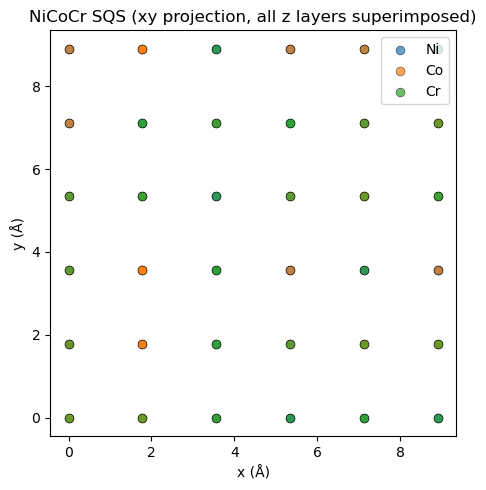

In [5]:
import matplotlib.pyplot as plt
import numpy as np
fig, ax = plt.subplots(figsize=(5, 5))
colors = {"Ni": "#1f77b4", "Co": "#ff7f0e", "Cr": "#2ca02c"}
for sp in ["Ni", "Co", "Cr"]:
    pts = np.array([a.position for a in sqs if a.symbol == sp])
    if len(pts):
        ax.scatter(pts[:, 0], pts[:, 1], c=colors[sp], label=sp, s=40,
                   alpha=0.7, edgecolors="black", linewidths=0.4)
ax.set_aspect("equal"); ax.set_xlabel("x (Å)"); ax.set_ylabel("y (Å)")
ax.set_title("NiCoCr SQS (xy projection, all z layers superimposed)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()


## Use the output

`sqs` is a standard ASE Atoms object — save in any format ASE supports.


In [6]:
out = Path.cwd() / "ni_co_cr_sqs.cif"
sqs.write(str(out))
print(f"Wrote {out}")
print(f"Lattice: {sqs.cell.cellpar()}")


Wrote /path/to/m_scraps/notebooks/ni_co_cr_sqs.cif
Lattice: [10.68 10.68 10.68 90.   90.   90.  ]


That's it — a 108-atom NiCoCr SQS in a few lines. The next notebook covers
targeting **non-zero** SRO values (literature CSRO patterns); the third covers
multi-sublattice HEB structures.
